# Digital Image Transmission over Multipath Channels

**Communication Systems · Sharif University of Technology · Fall 2024**  
**Farzan Aghaei**

A reproducible baseband simulation of image DCT quantization, antipodal binary signaling, Half-Sine/SRRC pulse shaping, symbol-spaced multipath, AWGN, matched filtering, and ZF/MMSE equalization. Includes spectrum and eye-diagram analysis, BER/SNR sweeps, image reconstruction, and alternate channel experiments.

The simulation uses a noiseless exchange of image dimensions and DCT quantization range; only the quantized coefficient bits travel through the channel. Energy is normalized per symbol. These assumptions are essential to interpreting the measured results.

## 1. Setup and block diagram

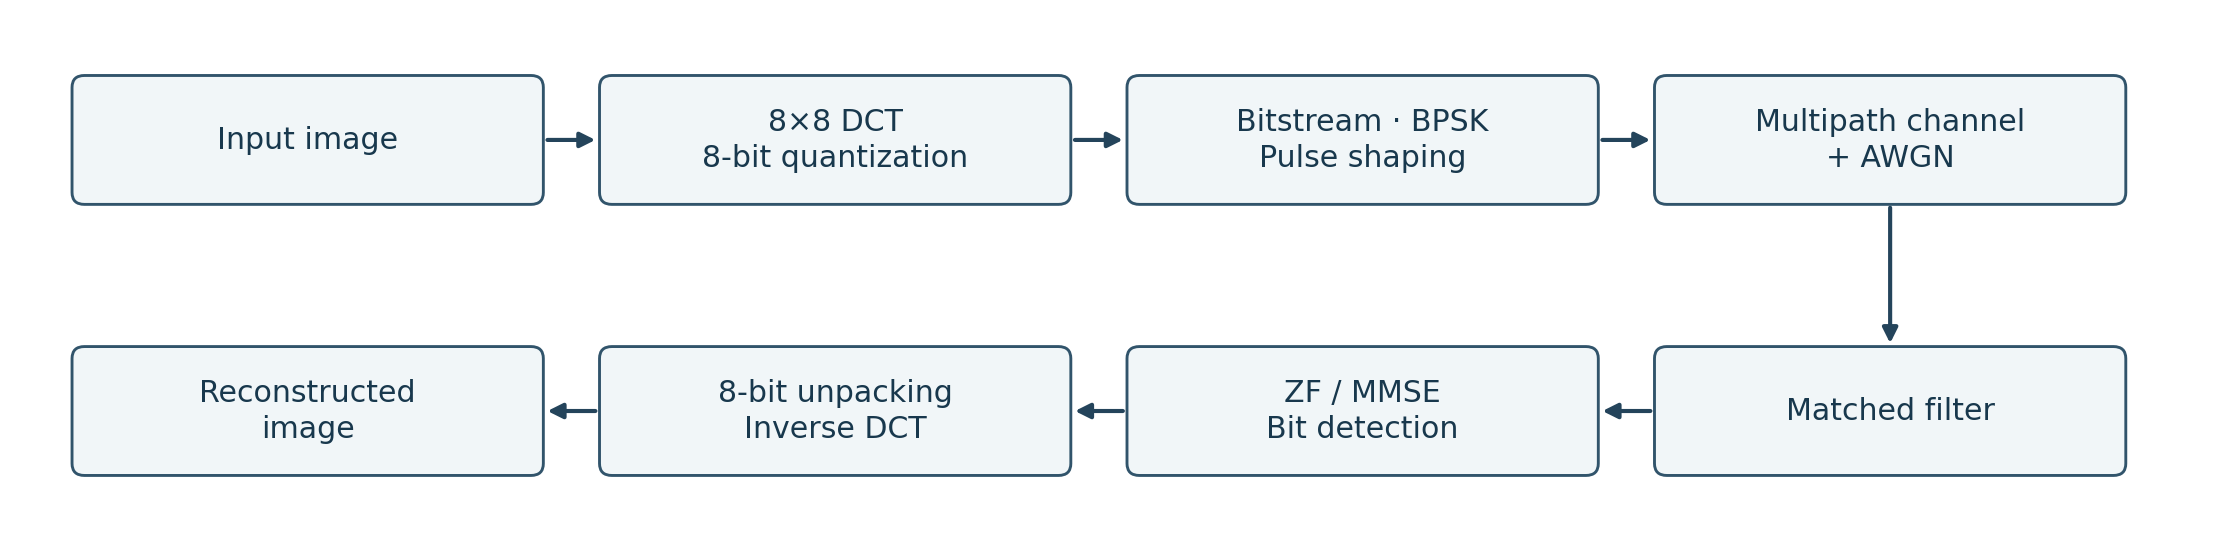

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from scipy.fft import dctn, idctn, rfft, irfft
from scipy.signal import fftconvolve, welch, freqz
from skimage.util import view_as_blocks
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

ROOT = Path.cwd()
ASSETS = ROOT / 'assets'
FIGURES = ROOT / 'figures'
RESULTS = ROOT / 'results'
for folder in (FIGURES, RESULTS): folder.mkdir(exist_ok=True)
SPS = 32                  # Samples per symbol; symbol period T=1
BETA = 0.5               # SRRC excess bandwidth
SEED = 2026
CHANNELS = {
    'Original 4-tap': np.array([1.0, 0.5, 0.75, -2/7]),
    'Alternate 6-tap': np.array([0.5, 1.0, 0.66, 0.25, 0.16, 0.04]),
    'Diffuse 6-tap': np.array([1.0, 0.2265, 0.19055, -0.08335, 0.155, 0.0025]),
}
plt.rcParams.update({'figure.dpi': 115, 'axes.grid': True,
                     'grid.alpha': 0.2, 'savefig.dpi': 165})

def savefig(name):
    plt.savefig(FIGURES / name, bbox_inches='tight')
    plt.show()

stages = [
    'Input image', '8×8 DCT\n8-bit quantization',
    'Bitstream · BPSK\nPulse shaping', 'Multipath channel\n+ AWGN',
    'Matched filter', 'ZF / MMSE\nBit detection',
    '8-bit unpacking\nInverse DCT', 'Reconstructed\nimage',
]
fig, ax = plt.subplots(figsize=(12.4, 3.0), facecolor='white')
ax.set_xlim(-0.25, 15.65)
ax.set_ylim(-0.1, 3.72)
ax.axis('off')
xs = [0.15, 4.0, 7.85, 11.70]
box_width, box_height = 3.35, 0.88
top_y, bottom_y = 2.40, 0.36
box_fc, box_ec = '#F1F6F8', '#31546B'
arrow_color = '#24445B'
for k, label in enumerate(stages):
    column = k if k < 4 else 7 - k
    x = xs[column]
    y = top_y if k < 4 else bottom_y
    rect = FancyBboxPatch((x, y), box_width, box_height,
                          boxstyle='round,pad=0.045,rounding_size=0.09',
                          linewidth=1.15, edgecolor=box_ec, facecolor=box_fc)
    ax.add_patch(rect)
    ax.text(x + box_width / 2, y + box_height / 2, label,
            ha='center', va='center', fontsize=12.0, color='#18384D',
            linespacing=1.32)

def arrow(p1, p2):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle='-|>',
                                mutation_scale=12.5, linewidth=1.65,
                                color=arrow_color, shrinkA=0, shrinkB=0,
                                connectionstyle='arc3,rad=0.0'))

for col in range(3):
    arrow((xs[col] + box_width + 0.075, top_y + box_height / 2),
          (xs[col + 1] - 0.075, top_y + box_height / 2))
arrow((xs[3] + box_width / 2, top_y - 0.07),
      (xs[3] + box_width / 2, bottom_y + box_height + 0.07))
for col in range(3, 0, -1):
    arrow((xs[col] - 0.075, bottom_y + box_height / 2),
          (xs[col - 1] + box_width + 0.075, bottom_y + box_height / 2))
fig.subplots_adjust(left=0.012, right=0.988, top=0.975, bottom=0.035)
savefig('01-system-diagram.png')

## 2. Block DCT, 8-bit coefficient mapping, and lossless bit packing

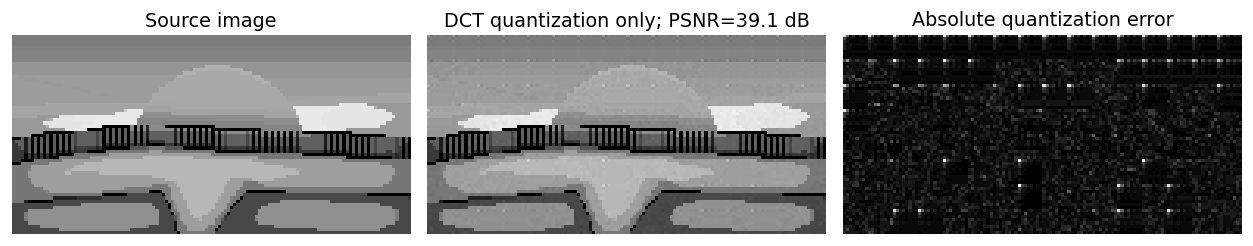

Image: (64, 128) payload: 65,536 bits | quantization-only PSNR: 39.09 dB


In [2]:
def encode_image(gray, block_size=8):
    if gray.ndim != 2 or gray.dtype != np.uint8:
        raise ValueError('Input must be an 8-bit grayscale image.')
    h,w=gray.shape
    pad_h=(-h)%block_size;pad_w=(-w)%block_size
    padded=np.pad(gray, ((0,pad_h),(0,pad_w)),mode='edge')
    blocks=view_as_blocks(padded.astype(np.float64)/255.0,(block_size,block_size))
    coeff=dctn(blocks,axes=(-2,-1),norm='ortho')
    lo=float(coeff.min());hi=float(coeff.max())
    if hi==lo: raise ValueError('Constant DCT coefficient range.')
    q=np.rint((coeff-lo)/(hi-lo)*255).clip(0,255).astype(np.uint8)
    bits=np.unpackbits(q.reshape(-1),bitorder='big')
    metadata={'shape':gray.shape,'padded':padded.shape,'coeff_shape':q.shape,
              'min':lo,'max':hi}
    return bits,metadata

def decode_image(bits,meta):
    bits=np.asarray(bits,dtype=np.uint8)
    expected=int(np.prod(meta['coeff_shape']))*8
    if bits.size!=expected: raise ValueError(f'Expected {expected} bits; got {bits.size}')
    q=np.packbits(bits,bitorder='big').reshape(meta['coeff_shape'])
    coef=q.astype(float)/255*(meta['max']-meta['min'])+meta['min']
    blocks=idctn(coef,axes=(-2,-1),norm='ortho')
    im=blocks.transpose(0,2,1,3).reshape(meta['padded'])
    h,w=meta['shape']
    return np.clip(np.rint(im[:h,:w]*255),0,255).astype(np.uint8)

def psnr(ref,est):
    mse=np.mean((ref.astype(float)-est.astype(float))**2)
    return float('inf') if mse==0 else 10*np.log10(255**2/mse)

def load_image(fname):
    img=cv2.imread(str(ASSETS/fname),cv2.IMREAD_GRAYSCALE)
    if img is None:raise FileNotFoundError(fname)
    return img

image=load_image('input-image.jpg')
bits,codec=encode_image(image)
reference=decode_image(bits,codec)
symbols=2*bits.astype(np.float64)-1
assert np.array_equal(np.unpackbits(np.packbits(bits)),bits)
fig,axes=plt.subplots(1,3,figsize=(11,3.2))
axes[0].imshow(image,cmap='gray',vmin=0,vmax=255);axes[0].set_title('Source image')
axes[1].imshow(reference,cmap='gray',vmin=0,vmax=255);axes[1].set_title(f'DCT quantization only; PSNR={psnr(image,reference):.1f} dB')
axes[2].imshow(cv2.absdiff(image,reference),cmap='gray');axes[2].set_title('Absolute quantization error')
for ax in axes:ax.axis('off')
fig.tight_layout();savefig('02-codec.png')
print('Image:', image.shape, 'payload:',f'{len(bits):,}','bits',
      '| quantization-only PSNR:',round(psnr(image,reference),2),'dB')

**Codec assumption.** An orthonormal 8×8 DCT is applied to each image block. Coefficients are linearly mapped to one unsigned byte using *global* extrema for the image. The byte sequence is transmitted MSB-first. The decoder is assumed to know the quantizer extrema and dimensions perfectly: this is a controlled channel experiment, **not** a complete self-describing image file format.

## 3. Half-Sine and SRRC pulse shaping: time, frequency, and pulse duration (Q1–Q4, Q17–Q20)

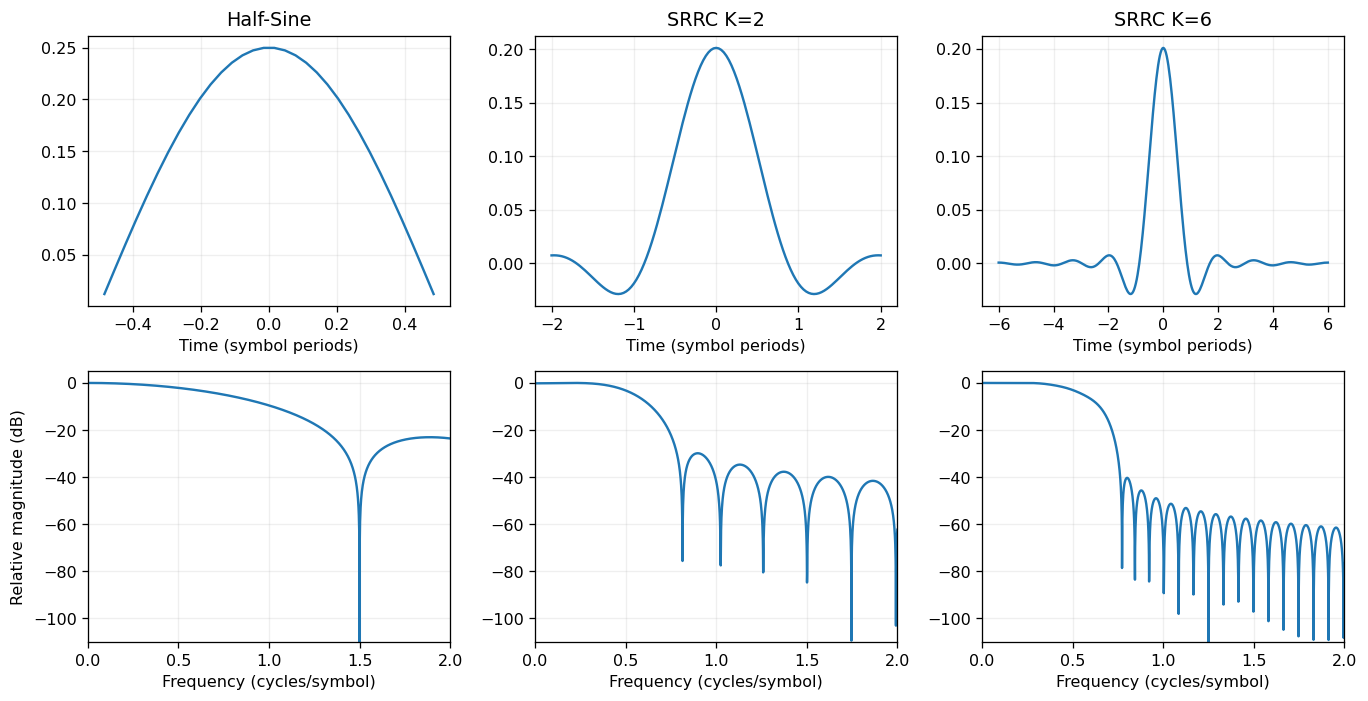

All pulse energies: {'Half-Sine': 1.0, 'SRRC K=2': 1.0, 'SRRC K=6': 1.0}
Neighbor-symbol ideal-channel ISI: {'Half-Sine': 0, 'SRRC K=2': np.float64(0.009718), 'SRRC K=6': np.float64(7e-05)}


In [3]:
def half_sine_pulse(sps=SPS):
    t=(np.arange(sps)+0.5)/sps
    p=np.sin(np.pi*t)
    return p/np.linalg.norm(p)

def srrc_pulse(beta=BETA,K=6,sps=SPS):
    if not (0<beta<=1):raise ValueError('0 < beta <= 1 required')
    t=np.arange(-K*sps,K*sps+1,dtype=float)/sps
    x=np.empty(t.shape)
    z0=np.isclose(t,0)
    z1=np.isclose(np.abs(t),1/(4*beta))&~z0
    other=~z0&~z1
    x[z0]=1-beta+4*beta/np.pi
    x[z1]=beta/np.sqrt(2)*((1+2/np.pi)*np.sin(np.pi/(4*beta))+
                            (1-2/np.pi)*np.cos(np.pi/(4*beta)))
    tau=t[other]
    x[other]=(np.sin(np.pi*(1-beta)*tau)+4*beta*tau*np.cos(np.pi*(1+beta)*tau))/(np.pi*tau*(1-(4*beta*tau)**2))
    return x/np.linalg.norm(x)

PULSES={'Half-Sine':half_sine_pulse(),
        'SRRC K=2':srrc_pulse(K=2), 'SRRC K=6':srrc_pulse(K=6)}
PULSES_SHORT={'Half-Sine':PULSES['Half-Sine'],'SRRC K=6':PULSES['SRRC K=6']}

def pulse_isi(pulse):
    auto=fftconvolve(pulse,pulse[::-1]);center=len(pulse)-1
    vals=[auto[center+k*SPS] for k in range(1,4) if center+k*SPS<len(auto)]
    return max([abs(v) for v in vals] or [0])

def occupied_bandwidth(x,fs=SPS,fraction=0.99):
    nfft=2**16
    p=np.abs(rfft(x,nfft))**2
    f=np.fft.rfftfreq(nfft,d=1/fs)
    cum=np.cumsum(p);cum/=cum[-1]
    return float(f[min(np.searchsorted(cum,fraction),len(f)-1)])

fig,axs=plt.subplots(2,3,figsize=(12,6.2))
for j,(name,pulse) in enumerate(PULSES.items()):
    t=(np.arange(len(pulse))-(len(pulse)-1)/2)/SPS
    axs[0,j].plot(t,pulse);axs[0,j].set_title(name)
    axs[0,j].set_xlabel('Time (symbol periods)')
    freq=np.fft.rfftfreq(2**15,1/SPS)
    spec=20*np.log10(np.maximum(np.abs(rfft(pulse,2**15)),1e-8))
    spec-=spec.max()
    axs[1,j].plot(freq,spec);axs[1,j].set_xlim(0,2.0);axs[1,j].set_ylim(-110,5)
    axs[1,j].set_xlabel('Frequency (cycles/symbol)')
    if j==0:axs[1,j].set_ylabel('Relative magnitude (dB)')
fig.tight_layout();savefig('03-pulse-responses.png')
print('All pulse energies:',{k:round(float(np.sum(p*p)),6) for k,p in PULSES.items()})
print('Neighbor-symbol ideal-channel ISI:',{k:round(pulse_isi(p),6) for k,p in PULSES.items()})

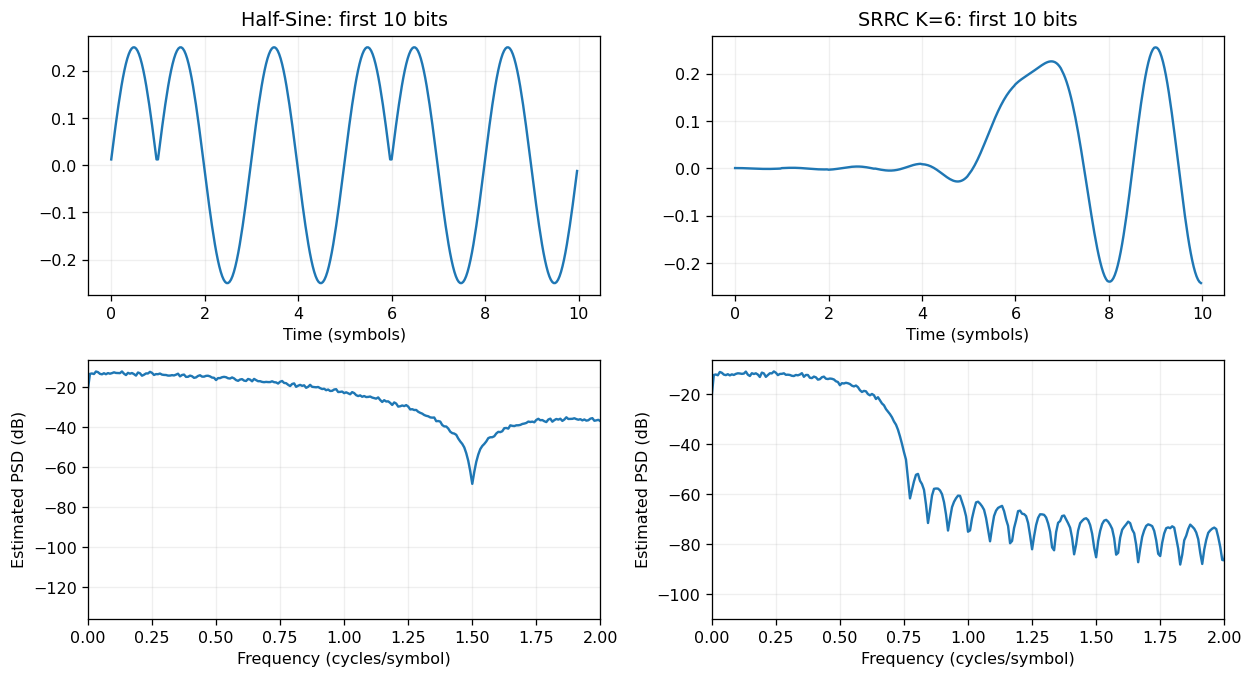

99% one-sided occupied bandwidth (pulse-only FFT estimate; cycles/symbol): {'Half-Sine': 1.1792, 'SRRC K=2': 0.6396, 'SRRC K=6': 0.6333}


In [4]:
def shape_bits(bit_vector,pulse):
    impulses=np.zeros(len(bit_vector)*SPS,dtype=float)
    impulses[::SPS]=2*np.asarray(bit_vector,dtype=float)-1
    return fftconvolve(impulses,pulse)

probe_bits=np.random.default_rng(SEED).integers(0,2,4096,dtype=np.uint8)
fig,ax=plt.subplots(2,2,figsize=(11,6))
for j,pname in enumerate(('Half-Sine','SRRC K=6')):
    p=PULSES[pname];wave=shape_bits(probe_bits,p)
    ax[0,j].plot(np.arange(320)/SPS,wave[:320]);ax[0,j].set_title(f'{pname}: first 10 bits')
    ax[0,j].set_xlabel('Time (symbols)')
    f,ps=welch(wave,fs=SPS,nperseg=4096)
    ax[1,j].plot(f,10*np.log10(np.maximum(ps,1e-13)));ax[1,j].set_xlim(0,2.0)
    ax[1,j].set_xlabel('Frequency (cycles/symbol)');ax[1,j].set_ylabel('Estimated PSD (dB)')
fig.tight_layout();savefig('04-modulated-waveforms-psd.png')
print('99% one-sided occupied bandwidth (pulse-only FFT estimate; cycles/symbol):',
      {name:round(occupied_bandwidth(p),4) for name,p in PULSES.items()})

The pulses have identical discrete energy. A Half-Sine pulse occupies one symbol and creates no ideal-channel ISI at symbol-spaced matched-filter decisions. A sufficiently long SRRC pair approximates the raised-cosine Nyquist response. Truncation introduces residual ISI and spectral leakage; increasing the span *K* improves the approximation without changing the ideal nominal roll-off bandwidth.

## 4. Channel, AWGN, matched filter, and equalizers (Q5–Q13)

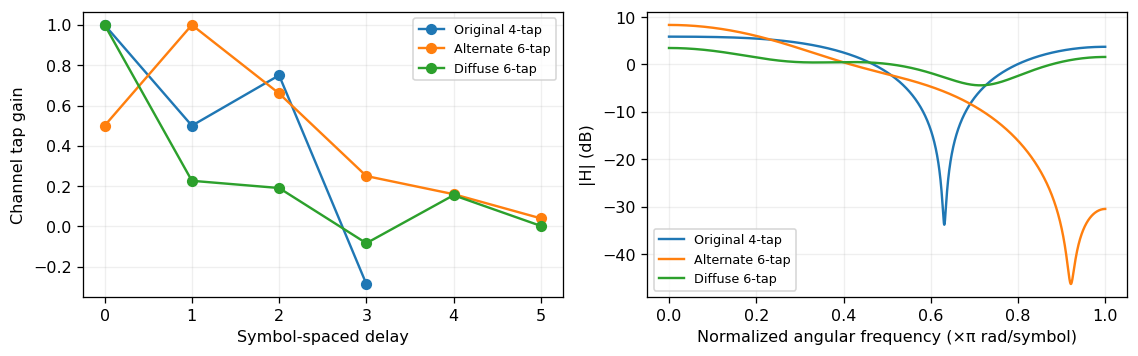

In [5]:
def upsample_taps(symbol_taps):
    h=np.zeros((len(symbol_taps)-1)*SPS+1)
    h[::SPS]=symbol_taps
    return h

def effective_channel(pulse,symbol_taps):
    h=upsample_taps(symbol_taps)
    cascade=fftconvolve(fftconvolve(pulse,h),pulse[::-1])
    align=len(pulse)-1
    first=int(np.ceil(-align/SPS))
    last=int(np.floor((len(cascade)-1-align)/SPS))
    lags=np.arange(first,last+1,dtype=int)
    return lags,cascade[align+lags*SPS]

def channel_and_matched(bit_vector,pulse,taps,noise_sigma,rng,return_wave=False):
    tx=shape_bits(bit_vector,pulse)
    path=fftconvolve(tx,upsample_taps(taps))
    noise=rng.normal(0,noise_sigma,size=len(path))
    mf=fftconvolve(path+noise,pulse[::-1])
    aligned=mf[len(pulse)-1:len(pulse)-1+len(bit_vector)*SPS:SPS]
    if aligned.size!=len(bit_vector):raise RuntimeError('Wrong decision timing')
    if return_wave:return aligned,(tx,path,mf)
    return aligned

def equalize(symbol_samples,pulse,taps,sigma,mode):
    # Circular frequency-domain approximation of the symbol-spaced MMSE/ZF detector.
    # Unit-variance antipodal symbols and unit-energy matched pulse;
    # MMSE uses white post-matched-noise approximation.
    lag,h=effective_channel(pulse,taps)
    n=len(symbol_samples)
    imp=np.zeros(n);np.add.at(imp,lag%n,h)
    H=rfft(imp)
    power=np.abs(H)**2
    if mode=='ZF': d=np.maximum(power,1e-10)
    elif mode=='MMSE': d=power+sigma**2
    else: raise ValueError(mode)
    return irfft(rfft(symbol_samples)*np.conjugate(H)/d,n)

def decide(vals): return np.asarray(vals>=0,dtype=np.uint8)
def ber(tx,rx):return float(np.mean(np.asarray(tx)!=np.asarray(rx)))
def link_result(transmitted,pulse,taps,sigma,seed):
    samples=channel_and_matched(transmitted,pulse,taps,sigma,np.random.default_rng(seed))
    return {r: decide(samples if r=='Uncorrected' else equalize(samples,pulse,taps,sigma,r))
            for r in ('Uncorrected','ZF','MMSE')}

fig,axs=plt.subplots(1,2,figsize=(10,3.2))
for name,taps in CHANNELS.items():
    t=np.arange(len(taps))
    axs[0].plot(t,taps,'o-',label=name)
    w,H=freqz(taps,worN=2048,whole=False)
    axs[1].plot(w/np.pi,20*np.log10(np.maximum(abs(H),1e-7)),label=name)
axs[0].set_xlabel('Symbol-spaced delay');axs[0].set_ylabel('Channel tap gain')
axs[1].set_xlabel('Normalized angular frequency (×π rad/symbol)')
axs[1].set_ylabel('|H| (dB)')
for a in axs:a.legend(fontsize=8)
fig.tight_layout();savefig('05-channel-responses.png')

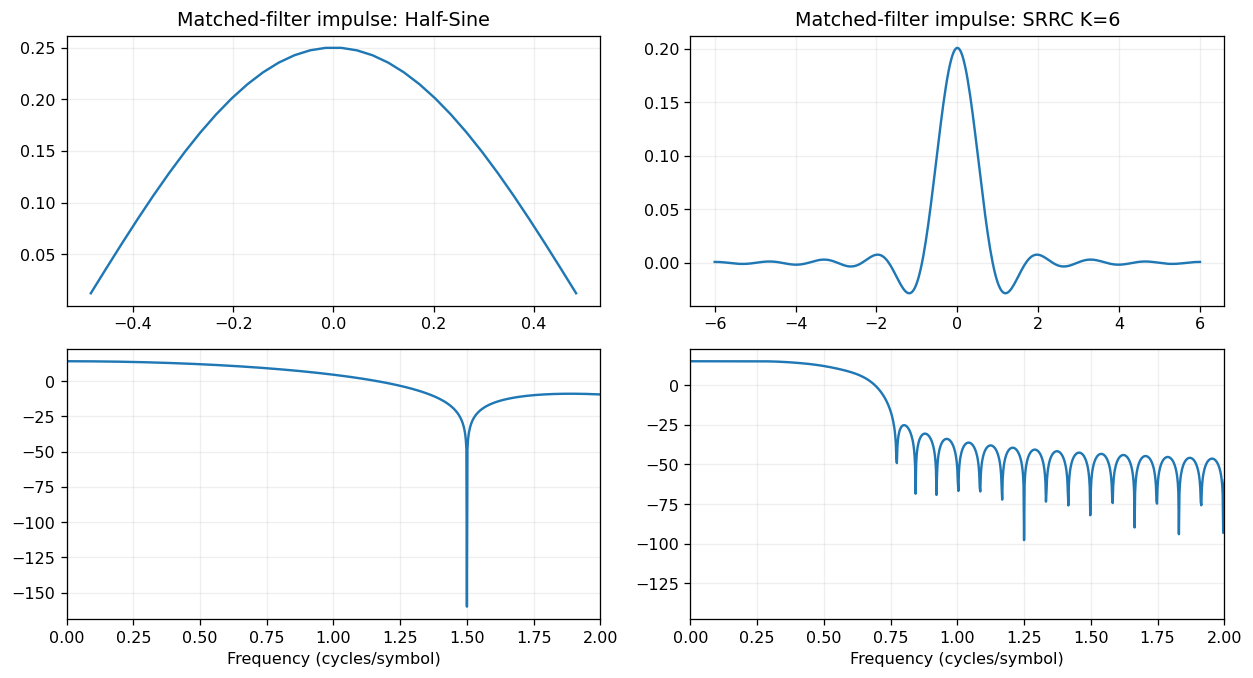

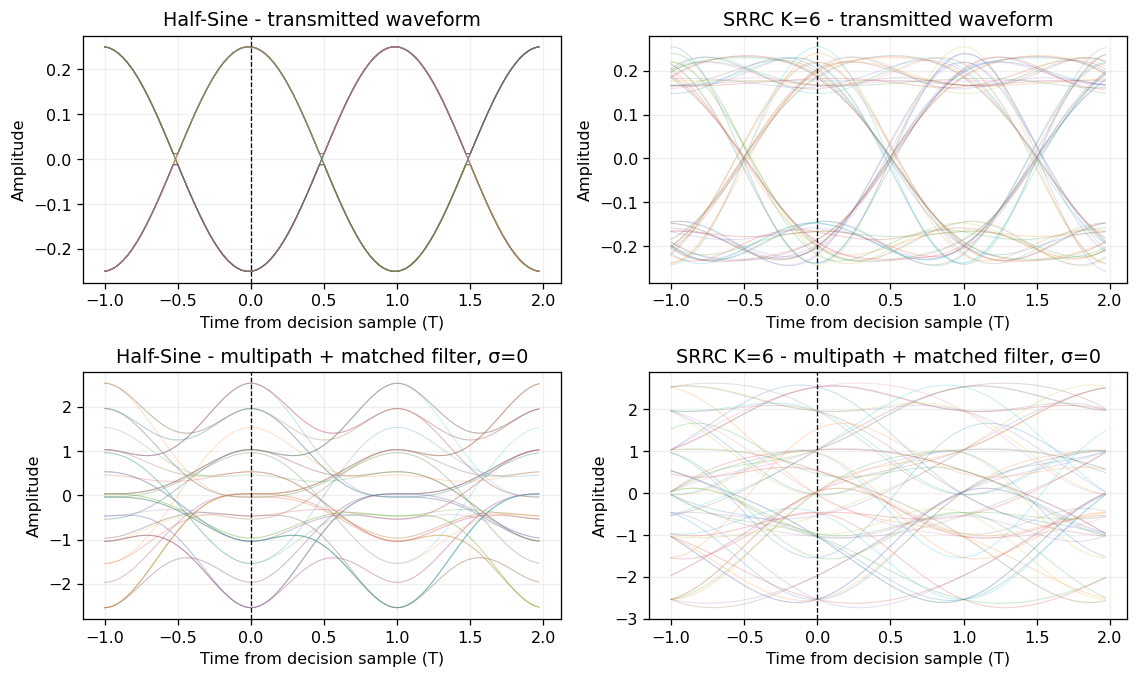

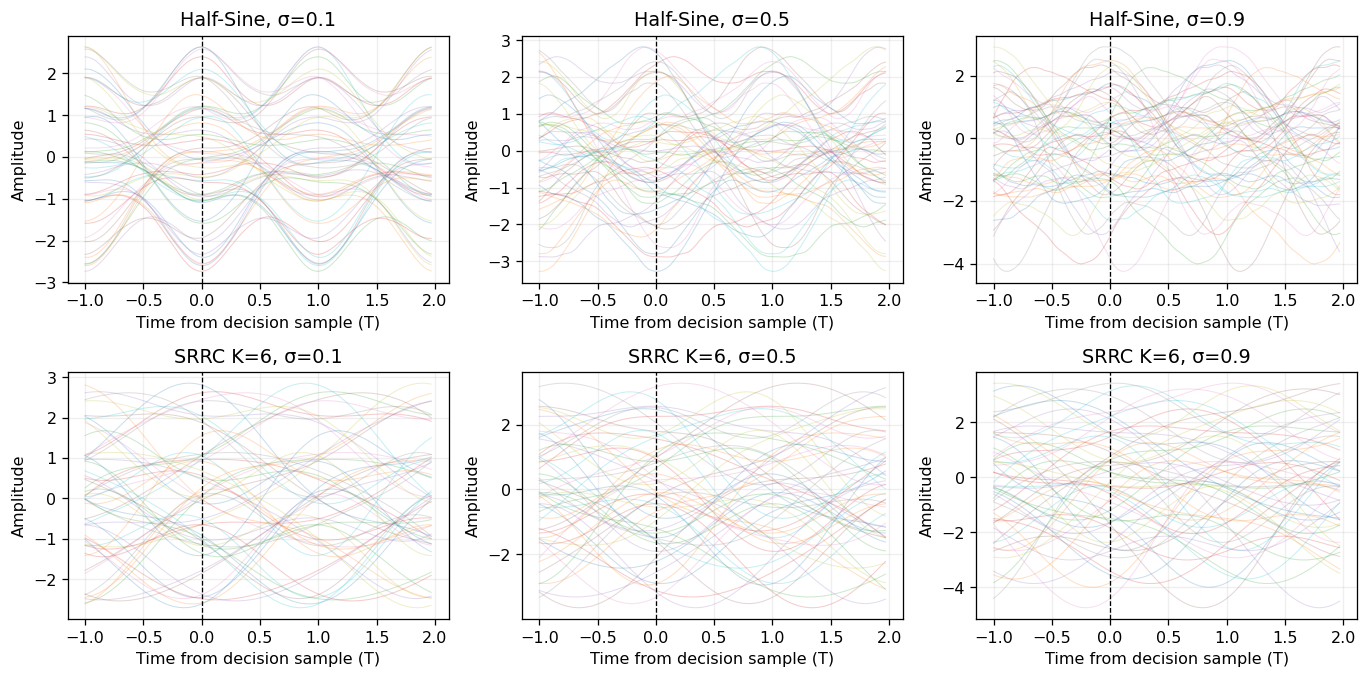

In [6]:
fig,ax=plt.subplots(2,2,figsize=(11,6))
for j,(name,p) in enumerate(PULSES_SHORT.items()):
    ax[0,j].plot((np.arange(len(p))-(len(p)-1)/2)/SPS,p)
    ax[0,j].set_title(f'Matched-filter impulse: {name}')
    f=np.fft.rfftfreq(2**14,d=1/SPS)
    H=abs(rfft(p[::-1],2**14))
    ax[1,j].plot(f,20*np.log10(np.maximum(H,1e-8)))
    ax[1,j].set_xlim(0,2)
    ax[1,j].set_xlabel('Frequency (cycles/symbol)')
fig.tight_layout();savefig('06-matched-filters.png')

def plot_eye(ax,stream,delay=0,trace_count=55,start=40):
    # Aligned at the actual best noiseless sampling epoch, offset=0 relative to peak.
    x=np.arange(-SPS,2*SPS)/SPS
    for k in range(start,start+trace_count):
        center=delay+k*SPS
        seg=stream[center-SPS:center+2*SPS]
        if len(seg)==len(x):ax.plot(x,seg,alpha=.23,lw=.65)
    ax.axvline(0,color='black',lw=.8,ls='--')
    ax.set_xlabel('Time from decision sample (T)')
    ax.set_ylabel('Amplitude')

probe=probe_bits[:640]
fig,axs=plt.subplots(2,2,figsize=(10,6))
for j,(name,p) in enumerate(PULSES_SHORT.items()):
    tx=shape_bits(probe,p)
    propagated=fftconvolve(tx,upsample_taps(CHANNELS['Original 4-tap']))
    mf=fftconvolve(propagated,p[::-1])
    plot_eye(axs[0,j],tx,delay=len(p)//2 if name=='Half-Sine' else len(p)//2)
    # raw pulse shaping eye, synchronization shown at pulse midpoint
    plot_eye(axs[1,j],mf,delay=len(p)-1)
    axs[0,j].set_title(f'{name} - transmitted waveform')
    axs[1,j].set_title(f'{name} - multipath + matched filter, σ=0')
fig.tight_layout();savefig('07-transmit-multipath-eyes.png')

fig,axs=plt.subplots(2,3,figsize=(12,6.0))
for row,(name,p) in enumerate(PULSES_SHORT.items()):
    for col,sigma in enumerate((0.1,0.5,0.9)):
        _,(_,_,mf)=channel_and_matched(probe,p,CHANNELS['Original 4-tap'],sigma,
                                     np.random.default_rng(SEED+10+col),return_wave=True)
        plot_eye(axs[row,col],mf,delay=len(p)-1)
        axs[row,col].set_title(f'{name}, σ={sigma}')
fig.tight_layout();savefig('08-noisy-matched-eye.png')

The decision sample is at the zero-delay peak of the transmit/matched-filter cascade (index `len(pulse)-1`, then every `SPS` samples). Eye diagrams show the **actual sample-rate waveform**. An eye need not be open after multipath; sampling alone cannot undo ISI. ZF and MMSE detection below operate on the **symbol-spaced effective response of the entire pulse/channel/matched-filter cascade**, not directly on the four raw path coefficients.

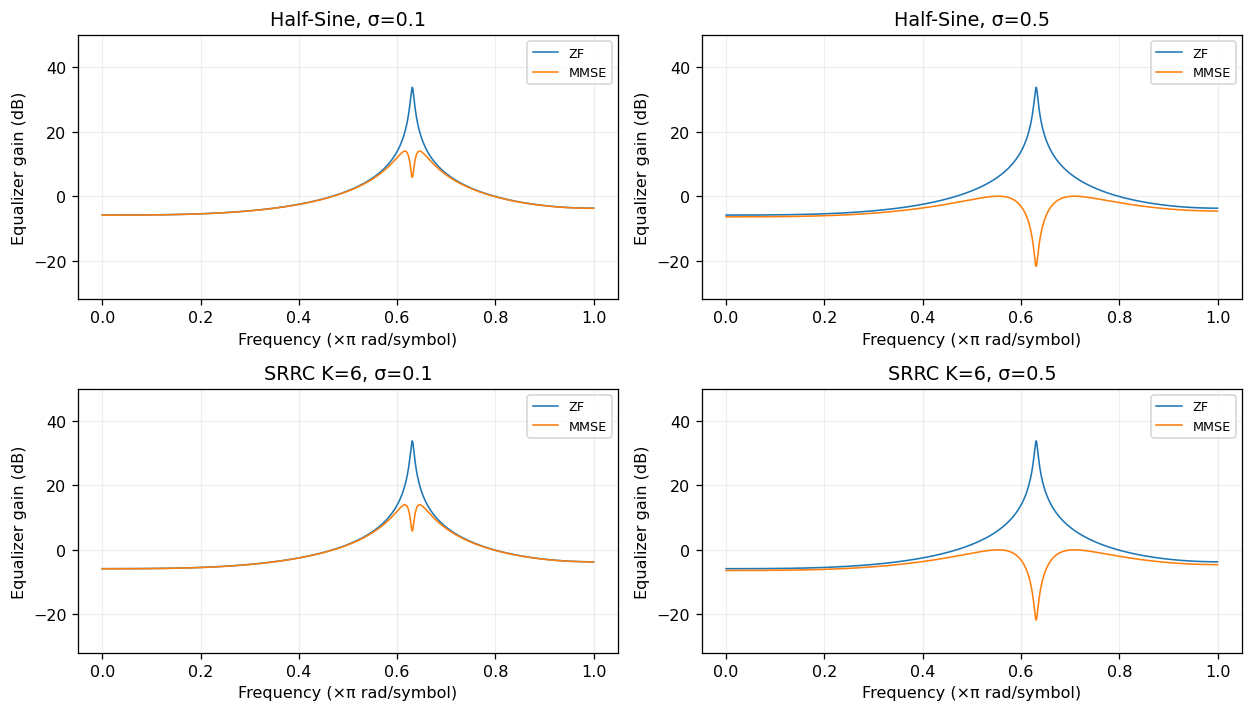

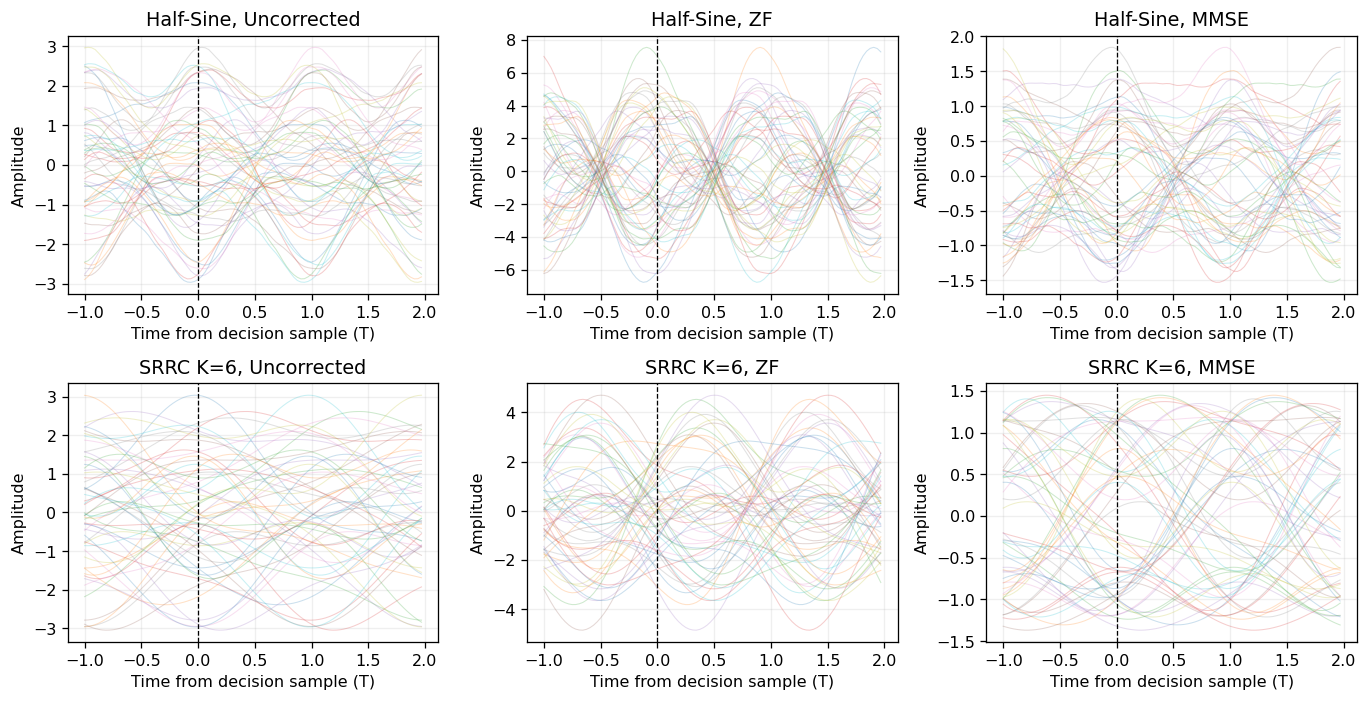

In [7]:
fig,axs=plt.subplots(2,2,figsize=(11,6.3))
for row,(name,p) in enumerate(PULSES_SHORT.items()):
    lags,g=effective_channel(p,CHANNELS['Original 4-tap'])
    w,H=freqz(g,worN=4096,whole=False)
    for col,sigma in enumerate((0.1,0.5)):
        power=np.abs(H)**2
        Qz=np.conj(H)/np.maximum(power,1e-10)
        Qm=np.conj(H)/(power+sigma**2)
        axs[row,col].plot(w/np.pi,20*np.log10(np.maximum(abs(Qz),1e-6)),label='ZF',lw=1)
        axs[row,col].plot(w/np.pi,20*np.log10(np.maximum(abs(Qm),1e-6)),label='MMSE',lw=1)
        axs[row,col].set_ylim(-32,50)
        axs[row,col].set_title(f'{name}, σ={sigma}')
        axs[row,col].set_xlabel('Frequency (×π rad/symbol)')
        axs[row,col].set_ylabel('Equalizer gain (dB)')
        axs[row,col].legend(fontsize=8)
fig.tight_layout();savefig('09-zf-mmse-frequency-response.png')

# A short waveform-rate ZF/MMSE diagnostic, to show equalized eyes.
# The BER experiments use the distinct symbol-rate equalizer above.
def waveform_equalizer(x,taps,sigma,kind):
    n=len(x)
    imp=upsample_taps(taps)
    H=rfft(imp,n)
    d=np.maximum(abs(H)**2,1e-10) if kind=='ZF' else abs(H)**2+sigma**2
    return irfft(rfft(x)*np.conj(H)/d,n)

fig,axs=plt.subplots(2,3,figsize=(12,6.2))
for row,(name,p) in enumerate(PULSES_SHORT.items()):
    sigma=.5
    _,(_,_,mf)=channel_and_matched(probe,p,CHANNELS['Original 4-tap'],sigma,
                                 np.random.default_rng(100),return_wave=True)
    for col,kind in enumerate(('Uncorrected','ZF','MMSE')):
        eql=mf if kind=='Uncorrected' else waveform_equalizer(mf,CHANNELS['Original 4-tap'],sigma,kind)
        plot_eye(axs[row,col],eql,delay=len(p)-1)
        axs[row,col].set_title(f'{name}, {kind}')
fig.tight_layout();savefig('10-waveform-equalizer-eyes.png')

**ZF stability and MMSE interpretation.** Exact ZF requires a nonzero channel response everywhere on the frequency axis; small magnitudes cause strong noise enhancement. A finite FFT-based ZF implementation necessarily uses a numerical floor. MMSE uses a noise-dependent regularization term under unit symbol energy and an approximately white matched-noise model. The waveform-rate eye-diagram equalizers are diagnostics; all tabulated BER/PSNR results use the symbol-rate effective-response equalizers defined in `equalize`.

## 5. Full image link: BER, received image, and SNR (Q14–Q16)

receiver      MMSE  Uncorrected       ZF
pulse                                   
Half-Sine  0.02411      0.34373  0.34042
SRRC K=2   0.02344      0.34483  0.34613
SRRC K=6   0.02466      0.34161  0.34267


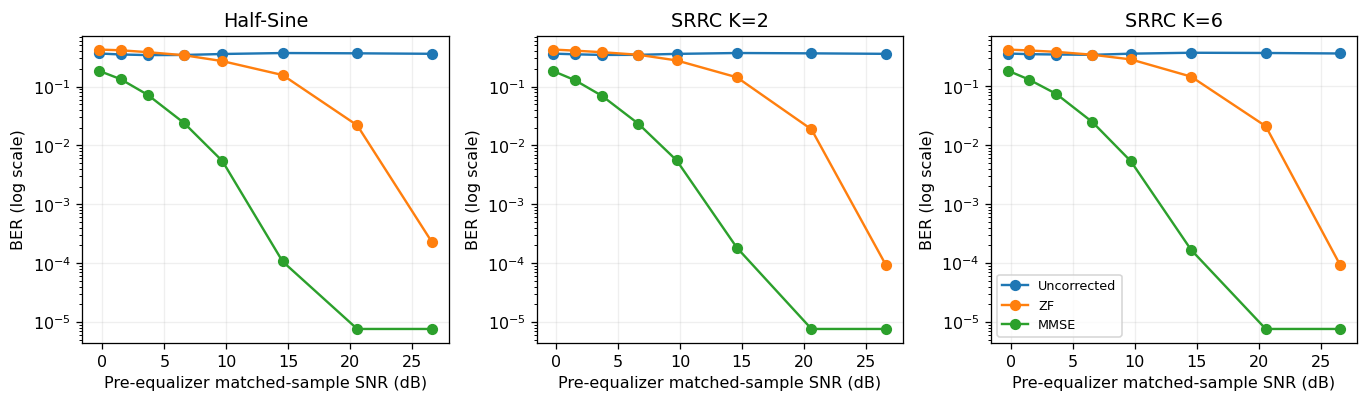

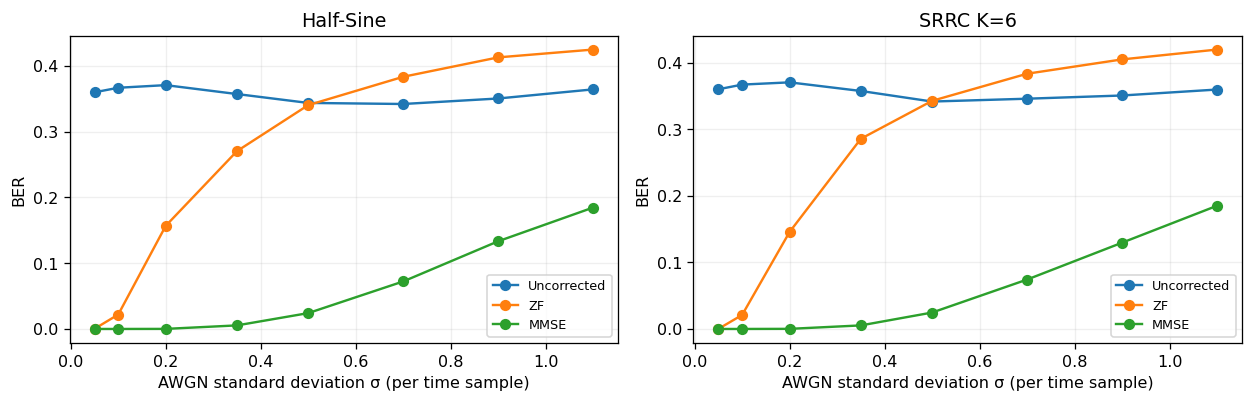

In [8]:
SIGMAS=(0.05,0.1,0.2,0.35,0.5,0.7,0.9,1.1)
original=CHANNELS['Original 4-tap']
records=[];detected={};raw_signal_power={}
for pi,(name,p) in enumerate(PULSES.items()):
    noiseless=channel_and_matched(bits,p,original,0,np.random.default_rng(0))
    power=float(np.mean(noiseless**2));raw_signal_power[name]=power
    for j,sigma in enumerate(SIGMAS):
        received=link_result(bits,p,original,sigma,seed=SEED+pi*111+j)
        for rx_type,out in received.items():
            errors=int(np.count_nonzero(bits!=out))
            records.append({'pulse':name,'sigma':sigma,
                            'matched_snr_db':10*np.log10(power/sigma**2),
                            'receiver':rx_type,'errors':errors,'bits':len(bits),
                            'ber':errors/len(bits),
                            'psnr_db':psnr(image,decode_image(out,codec))})
            detected[(name,sigma,rx_type)]=out
ber_frame=pd.DataFrame(records)
ber_frame.to_csv(RESULTS/'ber_snr.csv',index=False,float_format='%.8f')
print(ber_frame.query('sigma==0.5').pivot(index='pulse',columns='receiver',values='ber').round(5).to_string())

fig,axs=plt.subplots(1,3,figsize=(12,3.6))
for ax,(pname,p) in zip(axs,PULSES.items()):
    for rx_type in ('Uncorrected','ZF','MMSE'):
        sub=ber_frame[(ber_frame.pulse==pname)&(ber_frame.receiver==rx_type)]
        ax.semilogy(sub.matched_snr_db, np.maximum(sub.ber,1/len(bits)/2),'o-',label=rx_type)
    ax.set_title(pname);ax.set_xlabel('Pre-equalizer matched-sample SNR (dB)')
    ax.set_ylabel('BER (log scale)')
axs[-1].legend(fontsize=8)
fig.tight_layout();savefig('11-ber-vs-snr.png')

fig,axs=plt.subplots(1,2,figsize=(11,3.6))
for j,name in enumerate(('Half-Sine','SRRC K=6')):
    for mode in ('Uncorrected','ZF','MMSE'):
        sub=ber_frame[(ber_frame.pulse==name)&(ber_frame.receiver==mode)]
        axs[j].plot(sub.sigma,sub.ber,'o-',label=mode)
    axs[j].set_xlabel('AWGN standard deviation σ (per time sample)')
    axs[j].set_ylabel('BER');axs[j].set_title(name)
    axs[j].legend(fontsize=8)
fig.tight_layout();savefig('12-ber-vs-noise.png')

## 5.1. Measured post-equalizer decision-point SINR (Q15)

    pulse  sigma receiver  matched_snr_db  output_sinr_db  gain
Half-Sine   0.35       ZF           9.682          -4.794 1.000
Half-Sine   0.35     MMSE           9.682           8.276 0.841
Half-Sine   0.50       ZF           6.584          -7.769 1.000
Half-Sine   0.50     MMSE           6.584           5.861 0.741
 SRRC K=6   0.35       ZF           9.685          -4.419 1.000
 SRRC K=6   0.35     MMSE           9.685           8.272 0.841
 SRRC K=6   0.50       ZF           6.587          -7.963 1.000
 SRRC K=6   0.50     MMSE           6.587           5.929 0.742


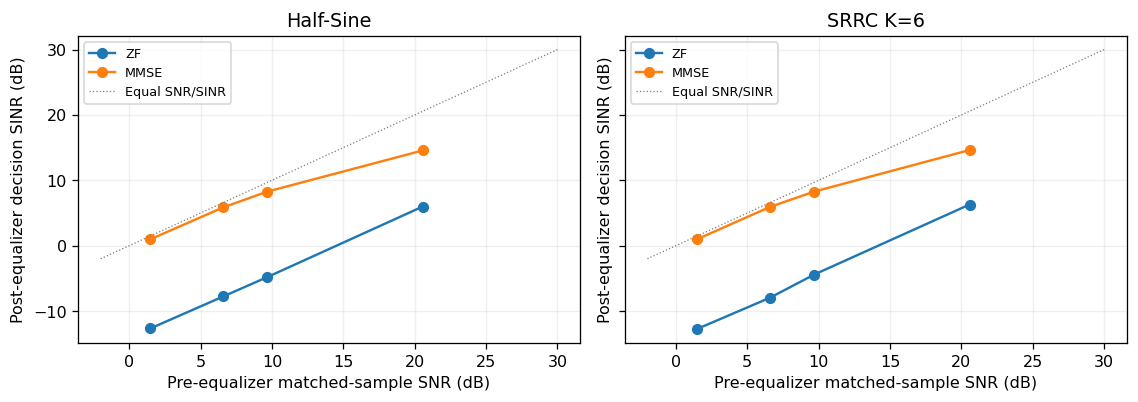

In [9]:
# Actual noise realizations are propagated through the matched filter and each equalizer.
# Estimate the useful symbol gain from noiseless output; all remaining error power
# (noise, residual ISI, numerical block boundaries) is included in the denominator.
sinr_rows=[]
for pi,(name,p) in enumerate(PULSES_SHORT.items()):
    clean_samples=channel_and_matched(bits,p,original,0,np.random.default_rng(0))
    for j,sigma in enumerate((.1,.35,.5,.9)):
        measured=channel_and_matched(bits,p,original,sigma,np.random.default_rng(555+pi*100+j))
        for mode in ('ZF','MMSE'):
            clean_eq=equalize(clean_samples,p,original,sigma,mode)
            noisy_eq=equalize(measured,p,original,sigma,mode)
            # Least-squares coherent gain, given the known transmitted symbols.
            gain=float(np.mean(clean_eq*symbols))
            residual=noisy_eq-gain*symbols
            sinr=10*np.log10(max(gain*gain,1e-20)/max(float(np.mean(residual**2)),1e-20))
            sinr_rows.append({'pulse':name,'sigma':sigma,'receiver':mode,
                              'matched_snr_db':10*np.log10(raw_signal_power[name]/sigma**2),
                              'output_sinr_db':sinr,'gain':gain})
sinr_frame=pd.DataFrame(sinr_rows)
sinr_frame.to_csv(RESULTS/'equalizer_output_sinr.csv',index=False,float_format='%.8f')
print(sinr_frame[sinr_frame.sigma.isin((.35,.5))].round(3).to_string(index=False))
fig,axs=plt.subplots(1,2,figsize=(10,3.6),sharey=True)
for ax,(name,p) in zip(axs,PULSES_SHORT.items()):
    for mode in ('ZF','MMSE'):
        ds=sinr_frame[(sinr_frame.pulse==name)&(sinr_frame.receiver==mode)]
        ax.plot(ds.matched_snr_db,ds.output_sinr_db,'o-',label=mode)
    ax.plot([-2,30],[-2,30],ls=':',color='gray',lw=.8,label='Equal SNR/SINR')
    ax.set_title(name);ax.set_xlabel('Pre-equalizer matched-sample SNR (dB)')
    ax.set_ylabel('Post-equalizer decision SINR (dB)')
    ax.legend(fontsize=8)
fig.tight_layout();savefig('18-output-sinr.png')

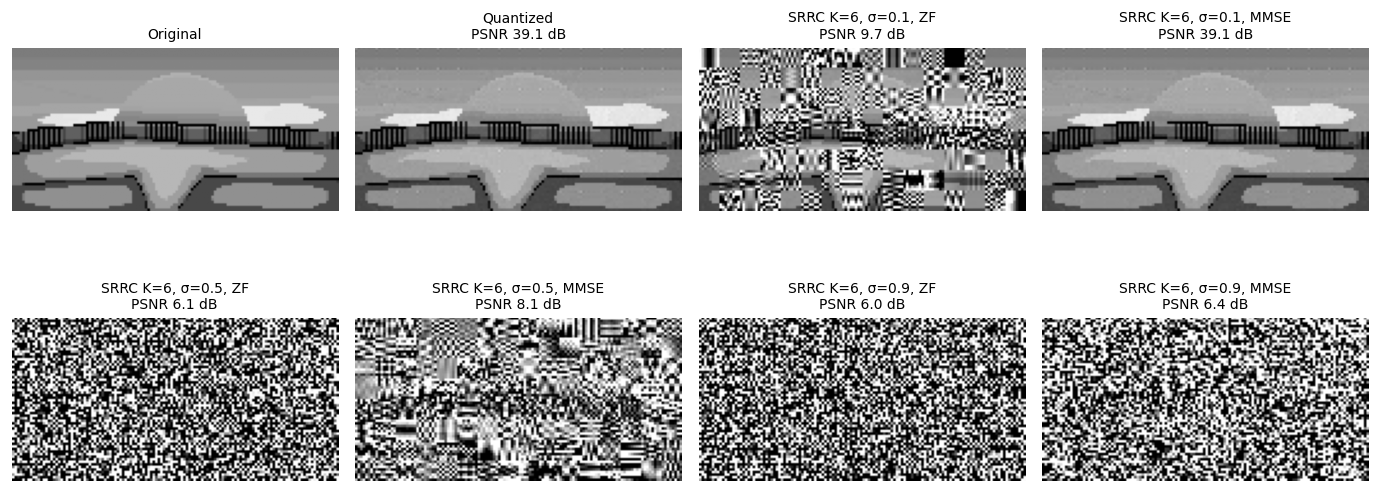

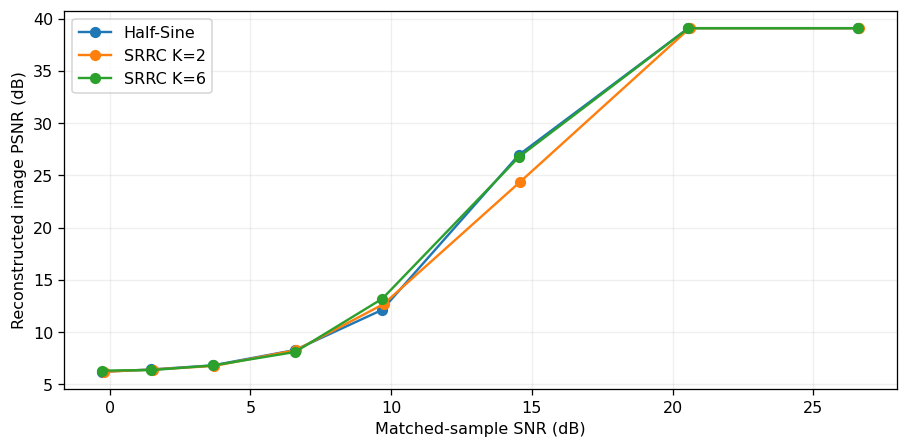

In [10]:
# Image reconstruction at three distinct noise levels and two receiver types.
variants=[('Original',image,None),('Quantized',reference,None)]
for s in (0.1,0.5,0.9):
    for rec in ('ZF','MMSE'):
        out=decode_image(detected[('SRRC K=6',s,rec)],codec)
        variants.append((f'SRRC K=6, σ={s}, {rec}',out,(s,rec)))
fig,axs=plt.subplots(2,4,figsize=(12.1,5.4))
for a,(title,img,key) in zip(axs.flat,variants):
    a.imshow(img,cmap='gray',vmin=0,vmax=255)
    score=psnr(image,img)
    a.set_title(f'{title}\nPSNR {score:.1f} dB' if np.isfinite(score) else title,fontsize=8.7)
    a.axis('off')
fig.tight_layout();savefig('13-image-reconstruction.png')

fig,ax=plt.subplots(figsize=(8,4))
for name in PULSES:
    subset=ber_frame[(ber_frame.pulse==name)&(ber_frame.receiver=='MMSE')]
    ax.plot(subset.matched_snr_db,subset.psnr_db,'o-',label=name)
ax.set_xlabel('Matched-sample SNR (dB)');ax.set_ylabel('Reconstructed image PSNR (dB)')
ax.legend();fig.tight_layout();savefig('14-psnr-vs-snr.png')

**Signal-to-noise definition.** Reported SNR is the ratio of mean squared **noiseless matched-filter decision samples before equalization** to the theoretical post-matched-filter AWGN variance σ² (pulse energy is one). This SNR includes signal-plus-ISI power and is **not** equalizer-output SINR or Eᵦ/N₀. ZF can lower BER at low noise and perform poorly near spectral nulls when noise is strong; MMSE trades residual ISI against noise enhancement. PSNR reflects both DCT quantization and bit errors.

## 6. Three input images and pulse-shape comparison (Q16–Q20)

   image     pulse receiver  sigma    ber  psnr_db
Original Half-Sine       ZF   0.35 0.2837   6.1345
Original Half-Sine     MMSE   0.35 0.0048  13.2650
Original  SRRC K=6       ZF   0.35 0.2767   6.2165
Original  SRRC K=6     MMSE   0.35 0.0048  12.9065
  Camera Half-Sine       ZF   0.35 0.2803   5.6153
  Camera Half-Sine     MMSE   0.35 0.0043  14.2029
  Camera  SRRC K=6       ZF   0.35 0.2768   5.6615
  Camera  SRRC K=6     MMSE   0.35 0.0045  12.6175
   Coins Half-Sine       ZF   0.35 0.2873   6.3738
   Coins Half-Sine     MMSE   0.35 0.0052  13.2559
   Coins  SRRC K=6       ZF   0.35 0.2816   6.3465
   Coins  SRRC K=6     MMSE   0.35 0.0062  12.6354


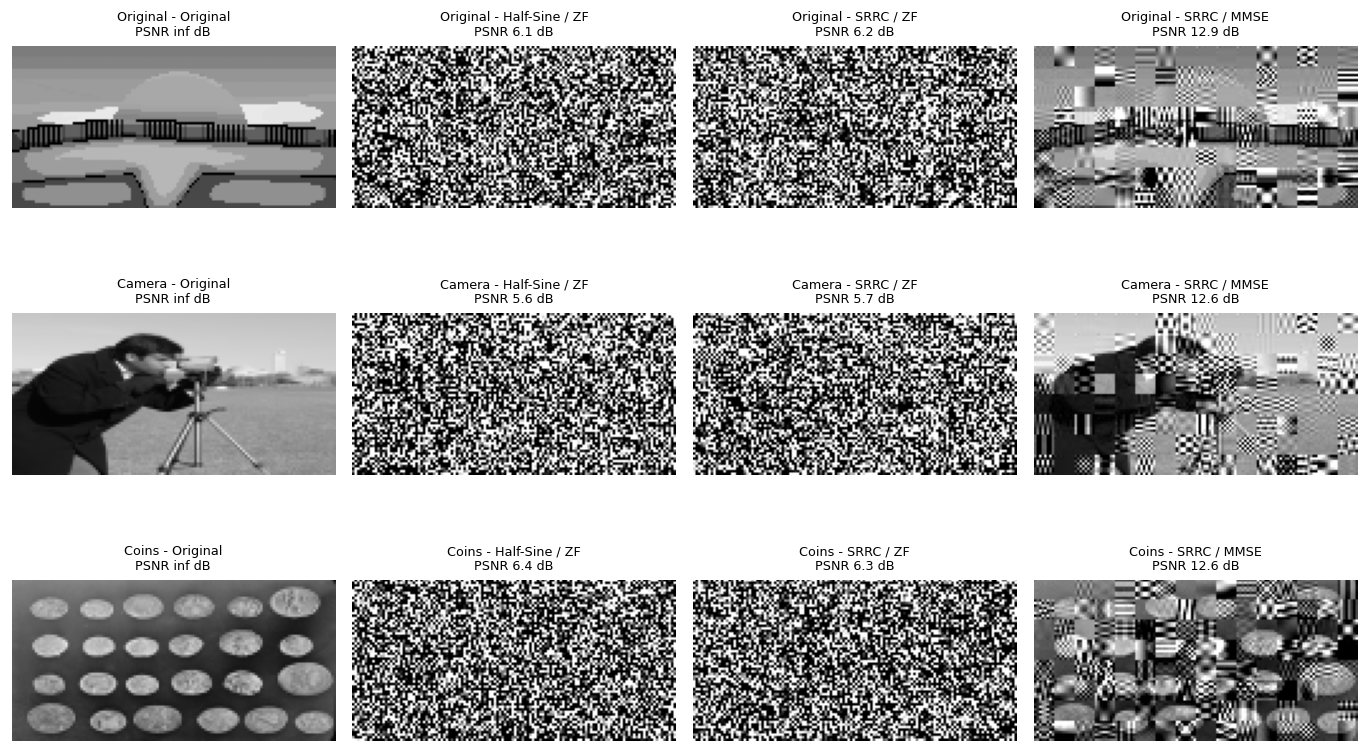

In [11]:
samples={'Original':image, 'Camera':load_image('camera.png'),
         'Coins':load_image('coins.png')}
three_rows=[];reconstructed={}
# Identical input dimension, codec, and noise std across the images.
for idx,(title,img) in enumerate(samples.items()):
    ib,meta=encode_image(img)
    for pname,p in PULSES_SHORT.items():
        outputs=link_result(ib,p,original,.35,seed=4000+idx)
        for mode,out_bits in outputs.items():
            out_img=decode_image(out_bits,meta)
            three_rows.append({'image':title,'pulse':pname,'receiver':mode,
                               'sigma':.35,'ber':ber(ib,out_bits),
                               'psnr_db':psnr(img,out_img)})
            reconstructed[(title,pname,mode)]=out_img
three_frame=pd.DataFrame(three_rows)
three_frame.to_csv(RESULTS/'three_images.csv',index=False,float_format='%.8f')
print(three_frame[three_frame.receiver.isin(['ZF','MMSE'])].round(4).to_string(index=False))

fig,axs=plt.subplots(3,4,figsize=(12,7.5))
for j,(title,img) in enumerate(samples.items()):
    options=[('Original',img),('Half-Sine / ZF',reconstructed[(title,'Half-Sine','ZF')]),
             ('SRRC / ZF',reconstructed[(title,'SRRC K=6','ZF')]),
             ('SRRC / MMSE',reconstructed[(title,'SRRC K=6','MMSE')])]
    for col,(label,disp) in enumerate(options):
        a=axs[j,col];a.imshow(disp,cmap='gray',vmin=0,vmax=255)
        a.set_title(f'{title} - {label}\nPSNR {psnr(img,disp):.1f} dB',fontsize=8)
        a.axis('off')
fig.tight_layout();savefig('15-three-image-comparison.png')

/tmp/ipykernel_1565/4219153305.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  off_energy=float(np.sum(g[lag!=0]**2)/max(g[lag==0]**2,1e-15))


 K  pulse_symbols  taps  ideal_adjacent_isi  occupied_bw_99pct  relative_isi_power_original_channel
 2              4   129             0.00972            0.63965                              0.90003
 4              8   257             0.00042            0.63184                              0.89404
 6             12   385             0.00007            0.63330                              0.89411
 8             16   513             0.00002            0.63428                              0.89412


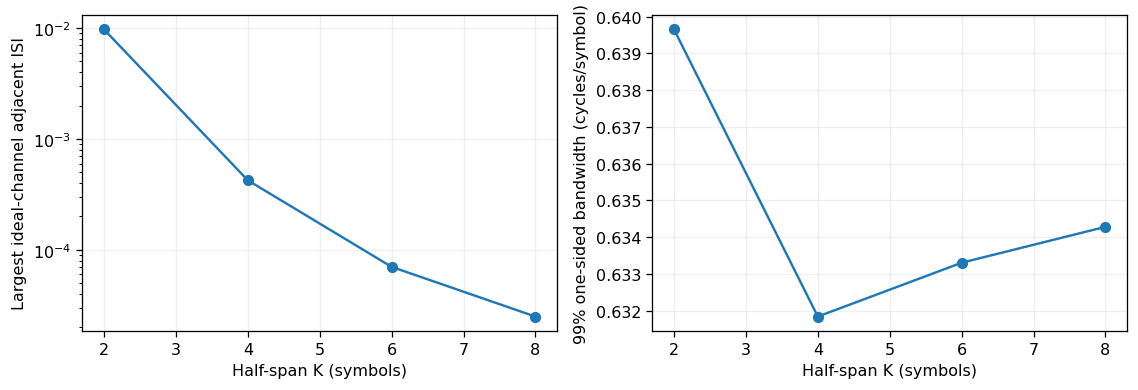

In [12]:
# Quantitative pulse-duration / ISI / spectral-spread analysis.
span_rows=[]
for K in (2,4,6,8):
    p=srrc_pulse(K=K)
    lag,g=effective_channel(p,original)
    off_energy=float(np.sum(g[lag!=0]**2)/max(g[lag==0]**2,1e-15))
    span_rows.append({'K':K,'pulse_symbols':2*K,'taps':len(p),
                      'ideal_adjacent_isi':pulse_isi(p),
                      'occupied_bw_99pct':occupied_bandwidth(p),
                      'relative_isi_power_original_channel':off_energy})
span_frame=pd.DataFrame(span_rows)
span_frame.to_csv(RESULTS/'pulse_span.csv',index=False,float_format='%.8f')
print(span_frame.round(5).to_string(index=False))
fig,axs=plt.subplots(1,2,figsize=(10,3.5))
axs[0].semilogy(span_frame.K,np.maximum(span_frame.ideal_adjacent_isi,1e-8),'o-')
axs[0].set_xlabel('Half-span K (symbols)');axs[0].set_ylabel('Largest ideal-channel adjacent ISI')
axs[1].plot(span_frame.K,span_frame.occupied_bw_99pct,'o-')
axs[1].set_xlabel('Half-span K (symbols)');axs[1].set_ylabel('99% one-sided bandwidth (cycles/symbol)')
fig.tight_layout();savefig('16-pulse-length-tradeoff.png')

## 7. Alternative multipath channels and robustness (Q21)

        channel     pulse  sigma  snr_db receiver    ber  psnr_db
 Original 4-tap Half-Sine   0.35  9.6818     MMSE 0.0048  12.9352
 Original 4-tap  SRRC K=6   0.35  9.6855     MMSE 0.0053  12.6175
Alternate 6-tap Half-Sine   0.35  9.2214     MMSE 0.0293  10.8533
Alternate 6-tap  SRRC K=6   0.35  9.2249     MMSE 0.0319  10.6902
  Diffuse 6-tap Half-Sine   0.35  9.2837     MMSE 0.0027  15.8080
  Diffuse 6-tap  SRRC K=6   0.35  9.2892     MMSE 0.0030  14.8822


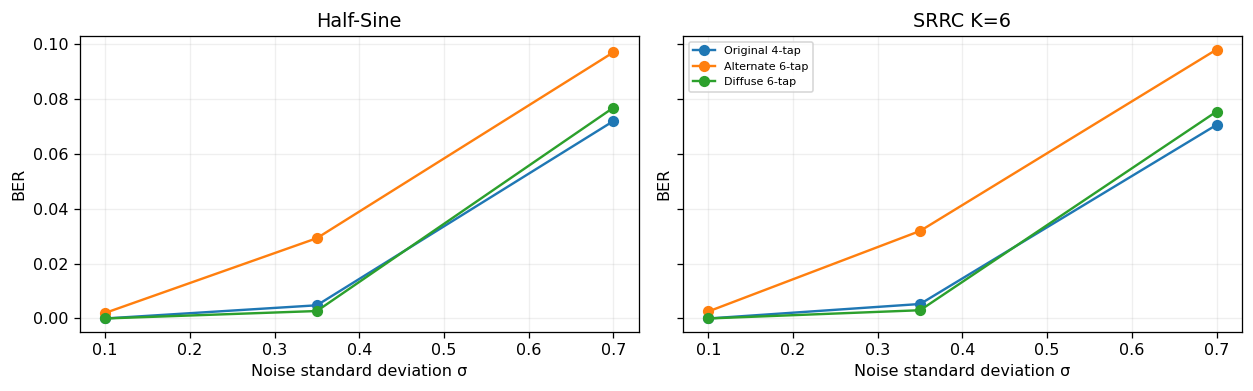

In [13]:
channel_rows=[];CHAN_SIGMAS=(.1,.35,.7)
for ci,(cname,taps) in enumerate(CHANNELS.items()):
    for pi,(pname,p) in enumerate(PULSES_SHORT.items()):
        power=np.mean(channel_and_matched(bits,p,taps,0,np.random.default_rng(0))**2)
        for j,sigma in enumerate(CHAN_SIGMAS):
            results=link_result(bits,p,taps,sigma,seed=7021+ci*100+pi*10+j)
            for mode,rx in results.items():
                channel_rows.append({'channel':cname,'pulse':pname,'sigma':sigma,
                                     'snr_db':10*np.log10(power/sigma**2),
                                     'receiver':mode,'ber':ber(bits,rx),
                                     'psnr_db':psnr(image,decode_image(rx,codec))})
channels_frame=pd.DataFrame(channel_rows)
channels_frame.to_csv(RESULTS/'channel_comparison.csv',index=False,float_format='%.8f')
print(channels_frame[(channels_frame.sigma==.35)&(channels_frame.receiver=='MMSE')].round(4).to_string(index=False))
fig,axs=plt.subplots(1,2,figsize=(11,3.5),sharey=True)
for j,pname in enumerate(PULSES_SHORT):
    for cname in CHANNELS:
        sub=channels_frame[(channels_frame.pulse==pname)&
                           (channels_frame.channel==cname)&
                           (channels_frame.receiver=='MMSE')]
        axs[j].plot(sub.sigma,sub.ber,'o-',label=cname)
    axs[j].set_title(pname);axs[j].set_xlabel('Noise standard deviation σ')
    axs[j].set_ylabel('BER')
axs[1].legend(fontsize=7)
fig.tight_layout();savefig('17-channel-robustness.png')

## 8. Engineering conclusions

- Energy-normalized Half-Sine and SRRC pulses differ in spectral containment, temporal support, and residual ISI; equal pulse energy does not imply identical performance in a dispersive channel.
- Matched filtering maximizes single-pulse SNR under white noise, but does not by itself invert the multipath channel.
- Frequency-domain ZF is vulnerable to amplification at spectral dips; MMSE regularization controls noise enhancement at the cost of some residual ISI. Results are channel- and noise-dependent, not a universal dominance claim.
- SRRC span *K* controls truncation-induced deviations from the ideal raised-cosine response and processing latency. Its nominal bandwidth depends primarily on the roll-off factor β, not on *K*.
- The image quality metric is PSNR relative to the original image. DCT coefficient quantization creates distortion even when BER is zero; transmission-induced errors create additional artifacts.
- The symbol-rate FFT equalizers use a circular block model (edges may have wrap-around artifacts), known channel response, and approximate white matched-noise statistics. Channel estimation, carrier/timing recovery, error-control coding, and quantizer metadata transport are outside this experiment.

The CSV files in `results/` contain the exact numerical outputs used in the report.